# 
**Bridge Condition Prediction System**

**Sprint 3: Optimization & Final Model**

This notebook starts from `bridge_data_clean.csv` (Sprint 1) and uses the same 80/20 stratified split as Sprints 1 and 2. The test set is **not touched until Step 5**. All feature selection and tuning use the training data only.

## Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/bridge_data_clean.csv")
print("Clean dataset:", df.shape)
print(df.columns.tolist())

Clean dataset: (592, 5)
['age_of_bridge', 'traffic_volume', 'material_type', 'maintenance_level', 'bridge_condition']


## Step 1: Feature Engineering

In [2]:
def make_features(data):
    """Create engineered features from the raw bridge columns."""
    out = data.copy()
    # Ratio: traffic carried per year of age
    out["traffic_per_year"] = out["traffic_volume"] / out["age_of_bridge"]
    # Interaction: cumulative load proxy (age x traffic, in thousands)
    out["age_x_traffic"] = out["age_of_bridge"] * out["traffic_volume"] / 1000
    # Domain-specific: age band (0 = <25 yrs, 1 = 25-50, 2 = 50-75, 3 = 75+)
    out["age_group"] = pd.cut(out["age_of_bridge"], bins=[0, 25, 50, 75, 100], labels=False)
    # Domain-specific: flag for bridges that are both old (> 50 years) and busy (> 2,000 vehicles)
    out["old_and_busy"] = ((out["age_of_bridge"] > 50) & (out["traffic_volume"] > 2000)).astype(int)
    return out

df_fe = make_features(df)
print(df_fe[["age_of_bridge", "traffic_volume", "traffic_per_year", "age_x_traffic", "age_group", "old_and_busy"]].head())

print("\nCorrelation of each feature with Bridge_Condition:")
print(df_fe[["age_of_bridge", "traffic_volume", "traffic_per_year", "age_x_traffic", "age_group", "old_and_busy", "bridge_condition"]]
      .corr()["bridge_condition"].drop("bridge_condition").round(3))

   age_of_bridge  traffic_volume  traffic_per_year  age_x_traffic  age_group  \
0             80              60          0.750000          4.800          3   
1             44            2516         57.181818        110.704          1   
2             61            4406         72.229508        268.766          2   
3             93            2082         22.387097        193.626          3   
4             62            4159         67.080645        257.858          2   

   old_and_busy  
0             0  
1             0  
2             1  
3             1  
4             1  

Correlation of each feature with Bridge_Condition:
age_of_bridge       0.385
traffic_volume      0.319
traffic_per_year   -0.120
age_x_traffic       0.559
age_group           0.407
old_and_busy        0.681
Name: bridge_condition, dtype: float64


Three new features were created, plus one domain flag:

| Feature | Type | Idea |
|---|---|---|
| `traffic_per_year` | Ratio | Traffic carried relative to the bridge's age |
| `age_x_traffic` | Interaction | Cumulative load proxy (older bridges with heavy traffic score highest) |
| `age_group` | Domain transformation | Age bands: under 25, 25-50, 50-75, 75+ years |
| `old_and_busy` | Domain flag | 1 if the bridge is older than 50 years **and** carries more than 2,000 vehicles |

*Aggregations (group statistics) do not apply here, because each row is a single bridge with no repeated entities to aggregate over.*

**Insights**
- `old_and_busy` has the strongest correlation with the target (**0.68**), followed by `age_x_traffic` (0.56). The original `age_of_bridge` and `traffic_volume` were 0.39 and 0.32.
- The `old_and_busy` thresholds come from the Sprint 1 EDA pattern. Step 5 checks that the training data alone gives the same thresholds.

In [3]:
# One-Hot Encoding and the same 80/20 stratified split as Sprint 1 and 2
df_encoded = pd.get_dummies(df_fe, columns=["material_type", "maintenance_level"], drop_first=True, dtype=int)

X = df_encoded.drop("bridge_condition", axis=1)
y = df_encoded["bridge_condition"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training:", X_train.shape, "| Testing:", X_test.shape)

Training: (473, 9) | Testing: (119, 9)


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

original_features = ["age_of_bridge", "traffic_volume", "material_type_Steel",
                     "maintenance_level_Bi-Annual", "maintenance_level_No-Maintenance"]

def cv_f1(features):
    pipe = make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42))
    return cross_val_score(pipe, X_train[features], y_train, cv=cv, scoring="f1").mean()

print("Random Forest CV F1 with original features  :", round(cv_f1(original_features), 3))
print("Random Forest CV F1 with engineered features:", round(cv_f1(list(X_train.columns)), 3))

Random Forest CV F1 with original features  : 0.478


Random Forest CV F1 with engineered features: 0.567


The engineered features raise the cross-validated F1 of a Random Forest from **0.478 to 0.567** with no other change, so the feature engineering is worth keeping.

## Step 2: Feature Selection

### 2.1 Correlation matrix

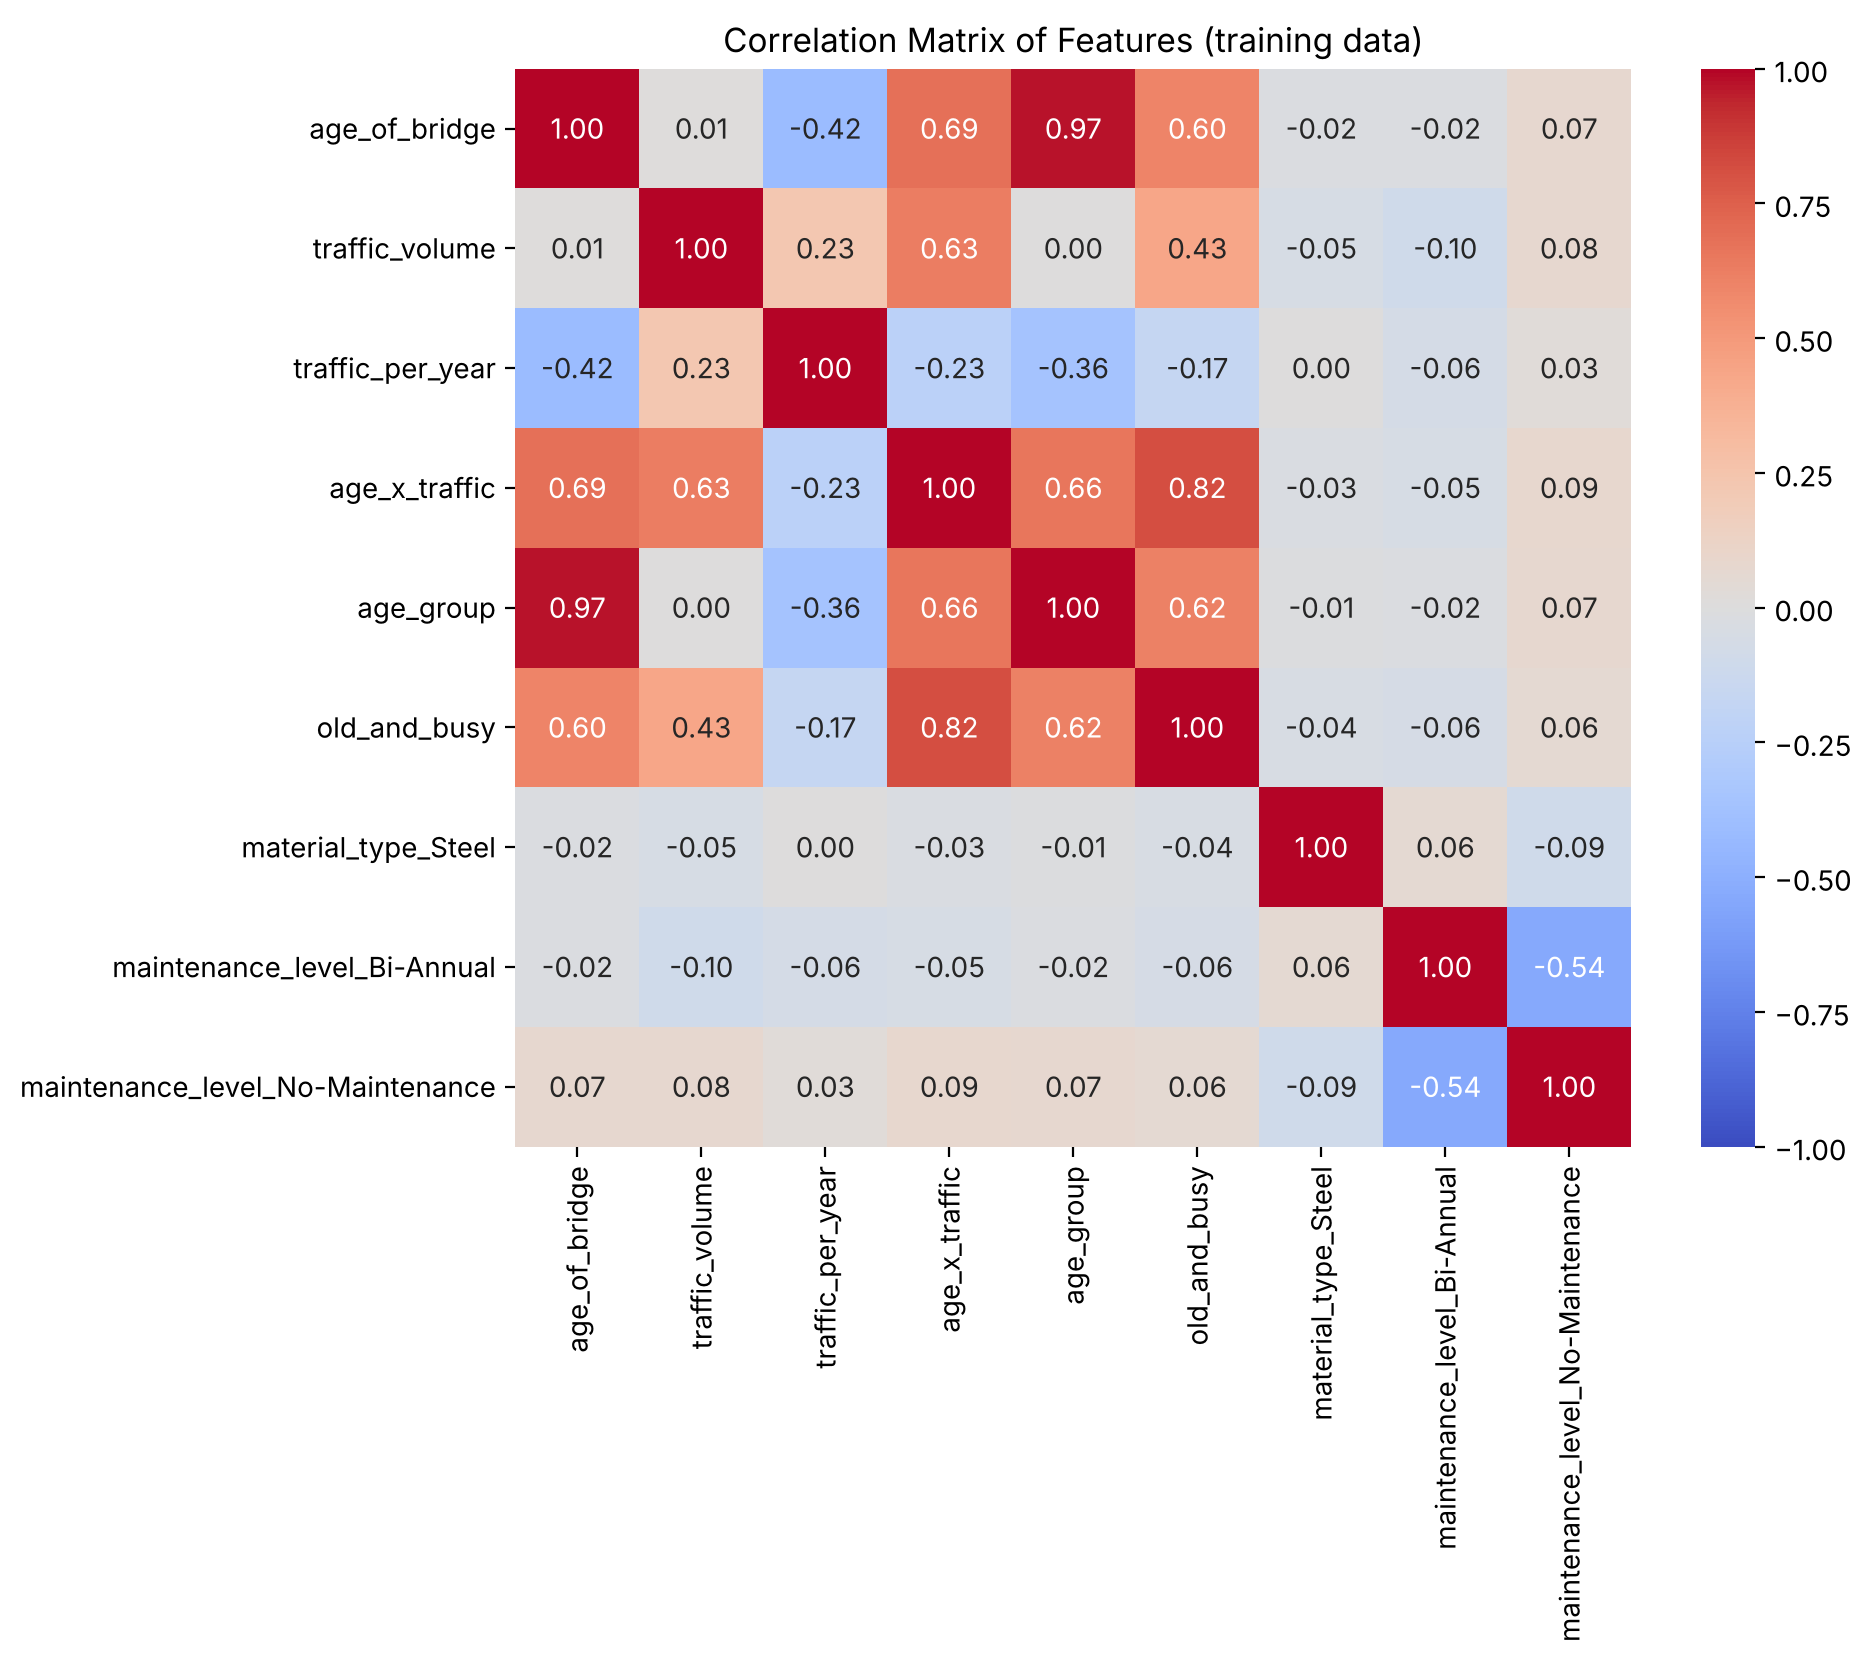

Highly correlated pairs (>0.8): [('age_of_bridge', 'age_group', np.float64(0.97)), ('age_x_traffic', 'old_and_busy', np.float64(0.82))]


In [5]:
plt.figure(figsize=(9, 7))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Features (training data)")
plt.show()

# Feature pairs with |correlation| > 0.8
corr = X_train.corr().abs()
pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns)
         for b in corr.columns[i + 1:] if corr.loc[a, b] > 0.8]
print("Highly correlated pairs (>0.8):", pairs)

Two pairs are highly correlated (above 0.8): `age_of_bridge` and `age_group` (0.97, since the group is just a binned copy of age), and `age_x_traffic` and `old_and_busy` (0.82). The redundant feature in each pair is dropped.

In [6]:
# age_group is a binned copy of age_of_bridge (r = 0.97);
# age_x_traffic overlaps with old_and_busy (r = 0.82), which is the stronger predictor
drop_cols = ["age_group", "age_x_traffic"]
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)
print("Remaining features:", X_train.columns.tolist())

Remaining features: ['age_of_bridge', 'traffic_volume', 'traffic_per_year', 'old_and_busy', 'material_type_Steel', 'maintenance_level_Bi-Annual', 'maintenance_level_No-Maintenance']


### 2.2 Feature importance

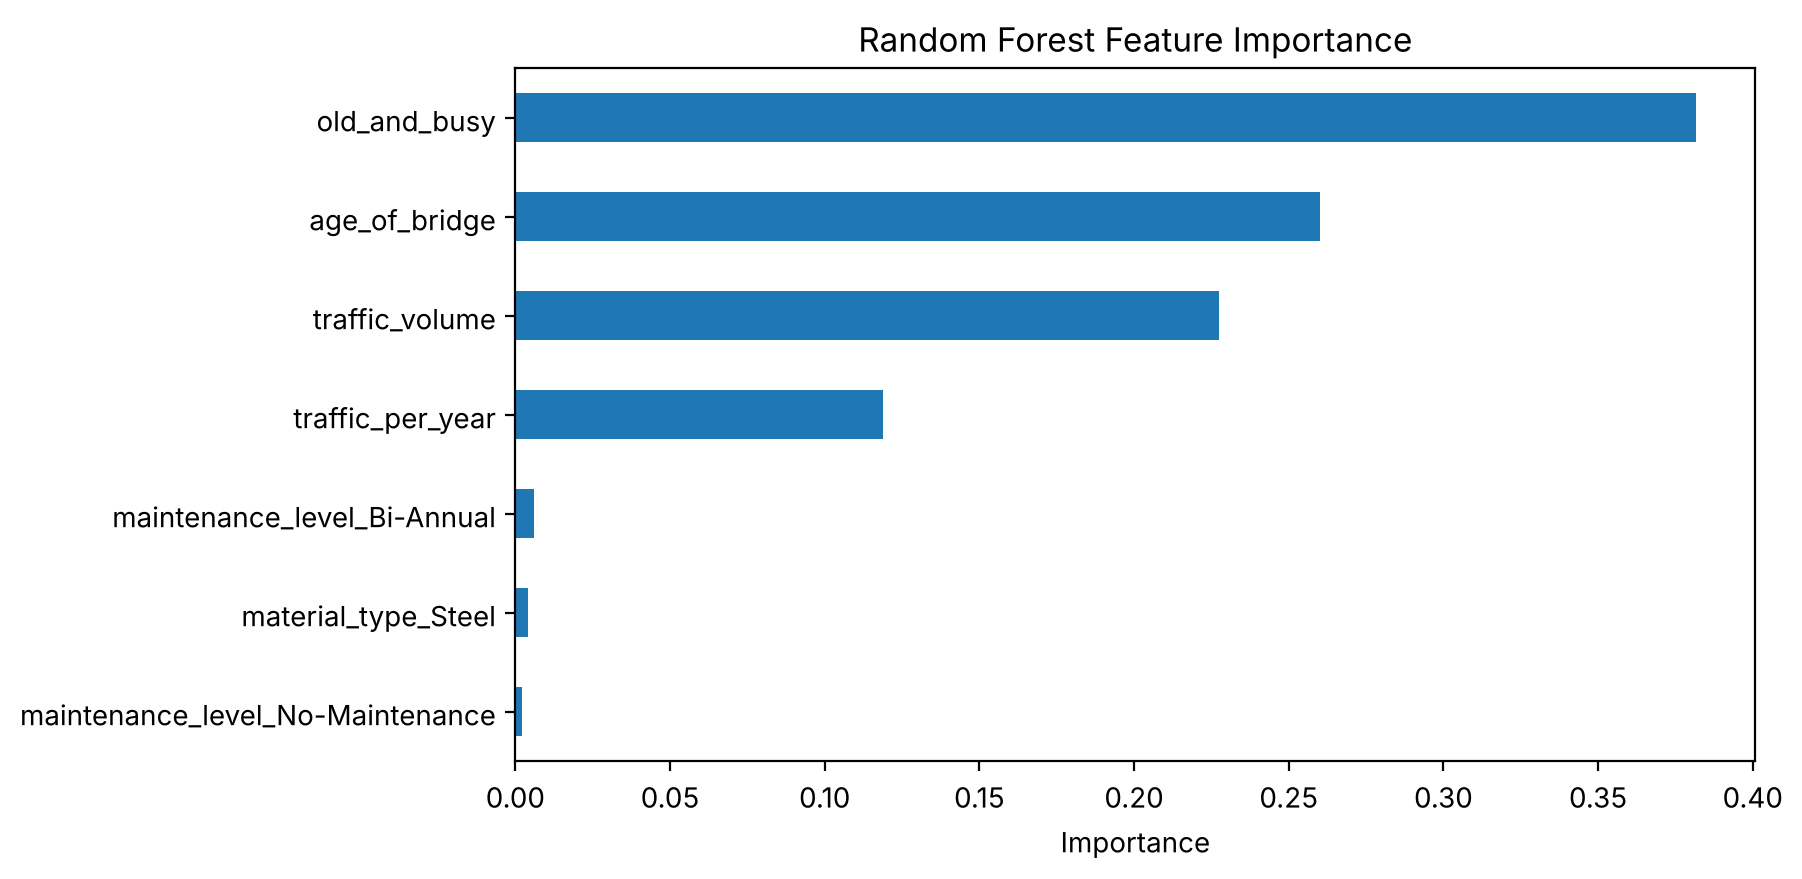

old_and_busy                        0.382
age_of_bridge                       0.260
traffic_volume                      0.227
traffic_per_year                    0.119
maintenance_level_Bi-Annual         0.006
material_type_Steel                 0.004
maintenance_level_No-Maintenance    0.002
dtype: float64


In [7]:
rf_imp = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(random_state=42, class_weight="balanced", max_depth=5, min_samples_leaf=5)
).fit(X_train, y_train)

importance = pd.Series(rf_imp[-1].feature_importances_, index=X_train.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 4.5))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()
print(importance.sort_values(ascending=False).round(3))

`old_and_busy` is the most important feature (0.382), followed by age (0.260), traffic (0.227) and `traffic_per_year` (0.119). **Material type and both maintenance columns have importance close to zero (0.002 to 0.006)**, which matches the Sprint 1 EDA where they showed almost no relationship with the target.

### 2.3 Recursive Feature Elimination (RFE)

In [8]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

rfe = RFE(
    RandomForestClassifier(random_state=42, class_weight="balanced", max_depth=5, min_samples_leaf=5),
    n_features_to_select=4,
)
rfe.fit(X_train, y_train)

rfe_table = pd.DataFrame({"Feature": X_train.columns, "RFE Rank": rfe.ranking_, "Selected": rfe.support_})
print(rfe_table.sort_values("RFE Rank").to_string(index=False))

selected_features = X_train.columns[rfe.support_].tolist()
print("\nSelected features:", selected_features)

                         Feature  RFE Rank  Selected
                   age_of_bridge         1      True
                  traffic_volume         1      True
                traffic_per_year         1      True
                    old_and_busy         1      True
     maintenance_level_Bi-Annual         2     False
             material_type_Steel         3     False
maintenance_level_No-Maintenance         4     False

Selected features: ['age_of_bridge', 'traffic_volume', 'traffic_per_year', 'old_and_busy']


In [9]:
def cv_f1_logreg(features):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
    return cross_val_score(pipe, X_train[features], y_train, cv=cv, scoring="f1").mean()

print("Balanced Logistic Regression CV F1, all", X_train.shape[1], "features :", round(cv_f1_logreg(list(X_train.columns)), 3))
print("Balanced Logistic Regression CV F1, selected", len(selected_features), "features:", round(cv_f1_logreg(selected_features), 3))

Balanced Logistic Regression CV F1, all 7 features : 0.722
Balanced Logistic Regression CV F1, selected 4 features: 0.722


RFE agrees with the importance scores and keeps four features: `age_of_bridge`, `traffic_volume`, `traffic_per_year` and `old_and_busy`. Removing the three weak features costs nothing: a balanced Logistic Regression scores the same cross-validated F1 (**0.722**) with 4 features as with all 7, and the model is simpler.

## Step 3: Hyperparameter Tuning

In [10]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from scipy.stats import loguniform

def make_pipe(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

X_tr = X_train[selected_features]

searches = {
    "Random Forest": GridSearchCV(
        make_pipe(RandomForestClassifier(random_state=42)),
        {"model__n_estimators": [100, 300],
         "model__max_depth": [3, 5, 8, None],
         "model__min_samples_leaf": [1, 3, 5, 10],
         "model__class_weight": [None, "balanced"]},
        cv=cv, scoring="f1", n_jobs=-1),
    "Logistic Regression": GridSearchCV(
        make_pipe(LogisticRegression(max_iter=1000)),
        {"model__C": [0.01, 0.1, 1, 10],
         "model__class_weight": [None, "balanced"]},
        cv=cv, scoring="f1", n_jobs=-1),
    "SVM": RandomizedSearchCV(
        make_pipe(SVC(random_state=42)),
        {"model__C": loguniform(0.1, 100),
         "model__gamma": loguniform(1e-3, 1),
         "model__class_weight": [None, "balanced"]},
        n_iter=40, cv=cv, scoring="f1", random_state=42, n_jobs=-1),
    "Decision Tree": RandomizedSearchCV(
        make_pipe(DecisionTreeClassifier(random_state=42)),
        {"model__max_depth": [2, 3, 4, 5, 6, 8],
         "model__min_samples_leaf": [1, 3, 5, 10, 20],
         "model__class_weight": [None, "balanced"]},
        n_iter=30, cv=cv, scoring="f1", random_state=42, n_jobs=-1),
}

for name, search in searches.items():
    search.fit(X_tr, y_train)
    print(name, "| best CV F1:", round(search.best_score_, 3))
    print("   best params:", {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
                              for k, v in search.best_params_.items()})

Random Forest | best CV F1: 0.722
   best params: {'class_weight': 'balanced', 'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 100}


Logistic Regression | best CV F1: 0.722
   best params: {'C': 0.01, 'class_weight': 'balanced'}


SVM | best CV F1: 0.722
   best params: {'C': np.float64(21.831), 'class_weight': None, 'gamma': np.float64(0.0029)}


Decision Tree | best CV F1: 0.727
   best params: {'min_samples_leaf': 10, 'max_depth': 4, 'class_weight': 'balanced'}


In [11]:
tuning_df = pd.DataFrame({
    "Model": list(searches.keys()),
    "Best CV F1": [s.best_score_ for s in searches.values()],
}).sort_values("Best CV F1", ascending=False).reset_index(drop=True)
print(tuning_df.round(3))

best_name = tuning_df.loc[0, "Model"]
print("\nBest model by cross-validated F1:", best_name)

                 Model  Best CV F1
0        Decision Tree       0.727
1        Random Forest       0.722
2  Logistic Regression       0.722
3                  SVM       0.722

Best model by cross-validated F1: Decision Tree


`GridSearchCV` was used for Random Forest and Logistic Regression, and `RandomizedSearchCV` for SVM and Decision Tree. All searches use 5-fold stratified cross-validation on the training data and optimize **F1 for the Good class**. Each pipeline scales the data inside every fold, so there is no leakage.

**Insights**
- Tuning mostly selected `class_weight="balanced"`, which tells the model to treat the rare Good class as more important.
- All four tuned models land within 0.005 of each other (**0.722 to 0.727**), so this is effectively a tie. This is a large improvement over the untuned Sprint 2 models, whose cross-validated F1 ranged from 0.32 to 0.55.
- The **Decision Tree** has the highest score (0.727). Since the models are tied, it is also the right choice on simplicity: it is the easiest to explain and the least likely to overfit.

## Step 4: Build Final Model

In [12]:
from sklearn.base import clone

best_params = searches[best_name].best_params_
print("Final model:", best_name)
print("Final features:", selected_features)
print("Final hyperparameters:", best_params)

final_model = clone(searches[best_name].best_estimator_)
final_model.fit(X_train[selected_features], y_train)
print("\nFinal model trained on", X_train.shape[0], "bridges")

Final model: Decision Tree
Final features: ['age_of_bridge', 'traffic_volume', 'traffic_per_year', 'old_and_busy']
Final hyperparameters: {'model__min_samples_leaf': 10, 'model__max_depth': 4, 'model__class_weight': 'balanced'}

Final model trained on 473 bridges


The final model is a Decision Tree (`max_depth=4`, `min_samples_leaf=10`, balanced class weights) trained on the full training set with the four selected features. The scaler and the classifier are stored together in one pipeline.

## Step 5: Final Evaluation (Unseen Test Data)

FINAL MODEL: Test Set Performance
Accuracy : 0.849
Precision: 0.526
Recall   : 1.0
F1 Score : 0.69
ROC-AUC  : 0.936

               precision    recall  f1-score   support

    Poor (0)       1.00      0.82      0.90        99
    Good (1)       0.53      1.00      0.69        20

    accuracy                           0.85       119
   macro avg       0.76      0.91      0.79       119
weighted avg       0.92      0.85      0.86       119



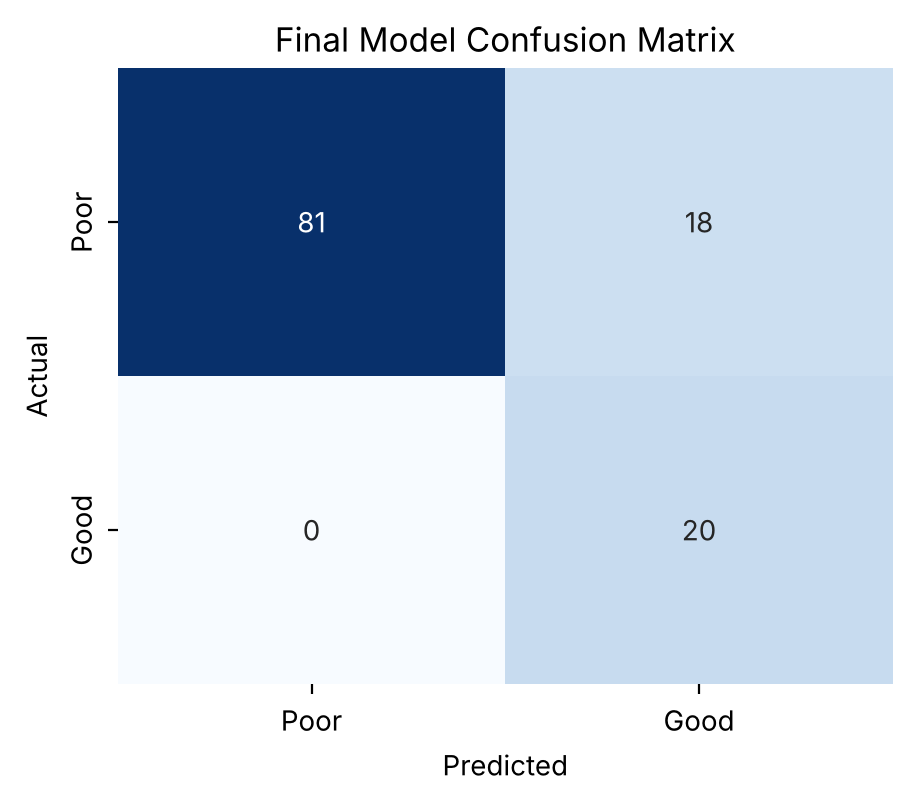

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

y_pred = final_model.predict(X_test[selected_features])

print("FINAL MODEL: Test Set Performance")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1 Score :", round(f1_score(y_test, y_pred), 3))
if hasattr(final_model, "predict_proba"):
    print("ROC-AUC  :", round(roc_auc_score(y_test, final_model.predict_proba(X_test[selected_features])[:, 1]), 3))

print("\n", classification_report(y_test, y_pred, target_names=["Poor (0)", "Good (1)"]))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Poor", "Good"], yticklabels=["Poor", "Good"])
plt.title("Final Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [14]:
# Sprint 2 best baseline: default Random Forest on the original features
s2 = make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42))
s2.fit(X_train[original_features], y_train)
p2 = s2.predict(X_test[original_features])

compare = pd.DataFrame({
    "Accuracy":  [accuracy_score(y_test, p2), accuracy_score(y_test, y_pred)],
    "Precision": [precision_score(y_test, p2), precision_score(y_test, y_pred)],
    "Recall (Good)": [recall_score(y_test, p2), recall_score(y_test, y_pred)],
    "Recall (Poor)": [recall_score(y_test, p2, pos_label=0), recall_score(y_test, y_pred, pos_label=0)],
    "F1 Score":  [f1_score(y_test, p2), f1_score(y_test, y_pred)],
}, index=["Sprint 2 baseline (Random Forest)", "Sprint 3 final model"])
print(compare.round(3))

print("\nOverfitting check (F1):")
print("  Train F1:", round(f1_score(y_train, final_model.predict(X_train[selected_features])), 3))
print("  Test F1 :", round(f1_score(y_test, y_pred), 3))

                                   Accuracy  Precision  Recall (Good)  \
Sprint 2 baseline (Random Forest)     0.891      0.667            0.7   
Sprint 3 final model                  0.849      0.526            1.0   

                                   Recall (Poor)  F1 Score  
Sprint 2 baseline (Random Forest)          0.929     0.683  
Sprint 3 final model                       0.818     0.690  

Overfitting check (F1):
  Train F1: 0.72
  Test F1 : 0.69


**Insights**
- The final model reaches **F1 0.69, ROC-AUC 0.936** on the unseen test set. Training F1 is 0.72, so **there is no overfitting** (the Sprint 2 Random Forest had 1.00 on training data).
- **Compared with Sprint 2, F1 is about the same (0.683 to 0.690); what changed is the type of error.** The final model finds **all 20 good bridges** (recall 0.70 to 1.00), but it also labels more poor bridges as good: 18 false alarms instead of 7 (Poor-class recall 0.93 to 0.82). Overall accuracy falls from 0.891 to 0.849 for the same reason.
- **Which model is better depends on which mistake costs more.** If calling a poor bridge "good" is the dangerous error (it could delay maintenance), the Sprint 2 Random Forest makes fewer of those. If missing a good bridge is the costly error, the final model is better. Confirm with the data owner that 1 = Good, because this decides the answer.

## Interpretation Insights

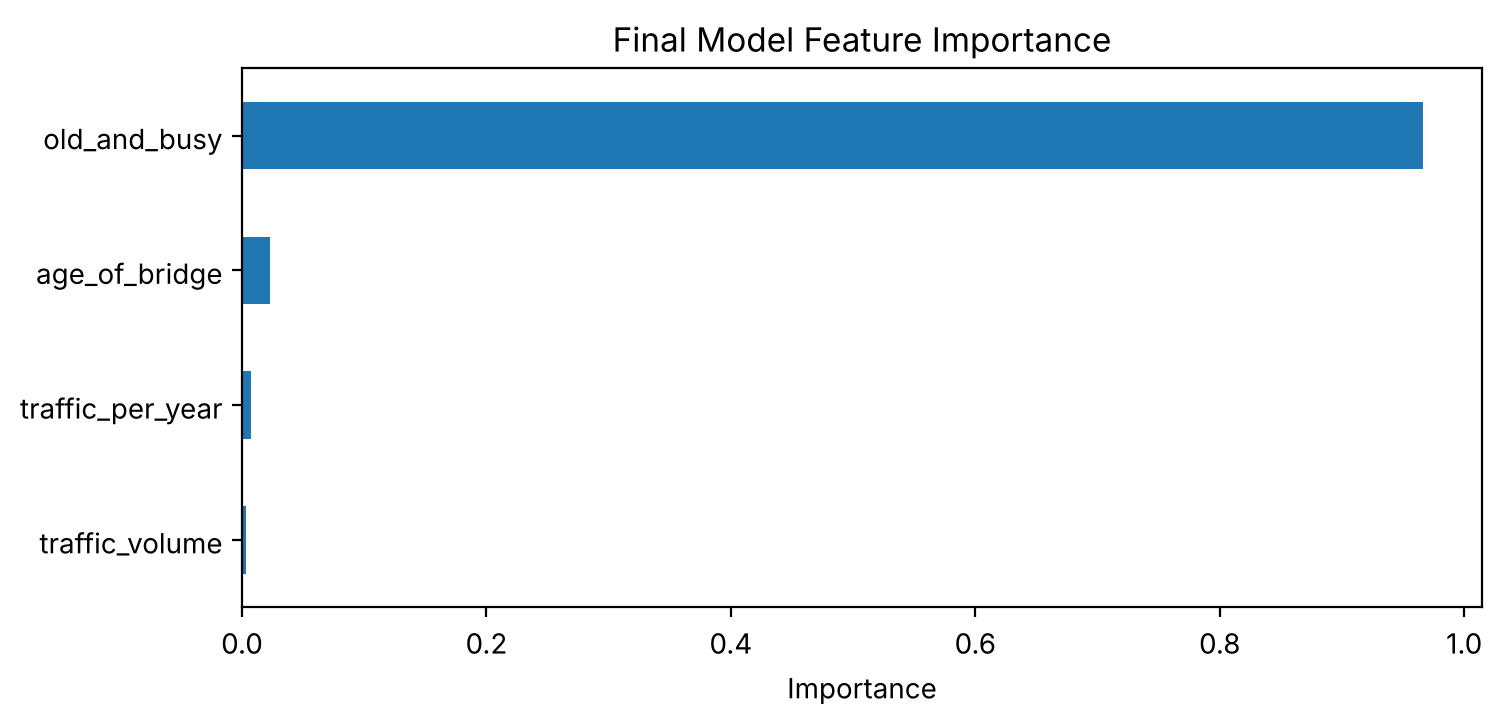

old_and_busy        0.966
age_of_bridge       0.023
traffic_per_year    0.007
traffic_volume      0.003
dtype: float64

Good bridges by zone:
                               good  bridges  share_good
age_over_50 traffic_over_2000                           
False       False                 0      123       0.000
            True                  0      178       0.000
True        False                 0      109       0.000
            True                101      182       0.555


In [15]:
model_step = final_model.named_steps["model"]

if hasattr(model_step, "feature_importances_"):
    imp = pd.Series(model_step.feature_importances_, index=selected_features).sort_values()
    imp.plot(kind="barh", figsize=(8, 3.5))
    plt.title("Final Model Feature Importance")
    plt.xlabel("Importance")
    plt.show()
    print(imp.sort_values(ascending=False).round(3))

# Share of good bridges in each age/traffic zone (full clean dataset)
zones = df_fe.assign(
    age_over_50=df_fe["age_of_bridge"] > 50,
    traffic_over_2000=df_fe["traffic_volume"] > 2000,
)
print("\nGood bridges by zone:")
print(zones.groupby(["age_over_50", "traffic_over_2000"])["bridge_condition"].agg(["sum", "count", "mean"]).round(3)
      .rename(columns={"sum": "good", "count": "bridges", "mean": "share_good"}))

In [16]:
# What do the training data say about the old_and_busy thresholds?
good_train = X_train[y_train == 1]
print("Youngest good bridge in training data :", good_train["age_of_bridge"].min(), "years")
print("Lowest-traffic good bridge in training:", good_train["traffic_volume"].min(), "vehicles")

# Inside the old-and-busy zone, how well can the features separate good from poor?
zone_mask = X_train["old_and_busy"] == 1
zone_features = ["age_of_bridge", "traffic_volume", "traffic_per_year",
                 "material_type_Steel", "maintenance_level_Bi-Annual", "maintenance_level_No-Maintenance"]
zone_auc = cross_val_score(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    X_train.loc[zone_mask, zone_features], y_train[zone_mask], cv=cv, scoring="roc_auc").mean()

print("\nBridges in the zone (training):", zone_mask.sum(), "| share good:", round(y_train[zone_mask].mean(), 3))
print("Cross-validated ROC-AUC inside the zone:", round(zone_auc, 3), "(0.5 = no better than a coin flip)")

# Best possible F1 if the model simply flags every bridge in the zone as Good (on test data)
test_zone = X_test["old_and_busy"] == 1
flag_pred = test_zone.astype(int)
print("\nSimple rule 'flag every old and busy bridge' on test data:")
print("  Precision:", round(precision_score(y_test, flag_pred), 3),
      "| Recall:", round(recall_score(y_test, flag_pred), 3),
      "| F1:", round(f1_score(y_test, flag_pred), 3))

Youngest good bridge in training data : 51 years
Lowest-traffic good bridge in training: 2039 vehicles

Bridges in the zone (training): 144 | share good: 0.562
Cross-validated ROC-AUC inside the zone: 0.551 (0.5 = no better than a coin flip)

Simple rule 'flag every old and busy bridge' on test data:
  Precision: 0.526 | Recall: 1.0 | F1: 0.69


**What the model learned**
1. **Every good bridge is both older than 50 years and carries more than 2,000 vehicles.** All 410 bridges outside that zone are poor, and 101 of the 182 bridges inside it (55.5%) are good. The training data alone gives the same cut-offs (youngest good bridge: 51 years, lowest-traffic good bridge: 2,039 vehicles).
2. **Inside that zone, nothing in the data separates good from poor.** Cross-validated ROC-AUC there is only 0.551 (0.5 is a coin flip), and material type and maintenance level add nothing.
3. **A one-line rule, "flag every bridge that is older than 50 and busier than 2,000", scores exactly the same test F1 (0.69) as the tuned model.** The model has captured everything these features can tell us, so more tuning will not help.
4. Such a clean cut-off is unusual for real inspection data, so it is worth asking how the Bridge_Condition label was generated.

**Recommendations**
- Use the model as a **screening tool**: bridges outside the old-and-busy zone can be treated as very unlikely to be in good condition.
- To go beyond F1 of about 0.7, new information is needed: inspection scores, structural details, repair history, or load ratings.

## Step 6: Model Serialization

In [17]:
import joblib

model_artifact = {
    "model": final_model,                 # scaler + classifier pipeline
    "features": selected_features,        # columns the model expects, in order
    "target": "bridge_condition (1 = Good, 0 = Poor)",
}
joblib.dump(model_artifact, "../models/bridge_condition_model.joblib")
print("Model saved: bridge_condition_model.joblib")

Model saved: bridge_condition_model.joblib


In [18]:
loaded = joblib.load("../models/bridge_condition_model.joblib")
loaded_model, loaded_features = loaded["model"], loaded["features"]

same = (loaded_model.predict(X_test[loaded_features]) == y_pred).all()
print("Reloaded model gives identical predictions:", same)

# Example: predict a new bridge from raw inputs
new_bridge = pd.DataFrame({"age_of_bridge": [80], "traffic_volume": [3500]})
new_bridge = make_features(new_bridge).reindex(columns=loaded_features, fill_value=0)
pred = loaded_model.predict(new_bridge)[0]
print("\nNew bridge (80 years old, 3,500 vehicles):", "Good" if pred == 1 else "Poor")

Reloaded model gives identical predictions: True

New bridge (80 years old, 3,500 vehicles): Good


The model is saved as `bridge_condition_model.joblib`. The file holds the full pipeline (scaler plus Decision Tree) and the list of feature names. Reloading it gives identical predictions to the in-memory model.

To score a new bridge, pass the raw age and traffic through the `make_features()` function from Step 1, then call `predict` on the four selected columns, as shown in the last cell.

## Sprint 3 Summary

| Deliverable | Result |
|---|---|
| Feature engineering | 4 new features; the strongest is `old_and_busy` (correlation 0.68 with the target) |
| Feature selection | Dropped 2 redundant features (correlation), then 3 weak ones (importance and RFE); kept 4 |
| Tuning | `GridSearchCV` and `RandomizedSearchCV`, 5-fold F1; CV F1 improved from 0.32-0.55 (Sprint 2 models) to 0.72-0.73 |
| Final model | Decision Tree: test accuracy 0.849, precision 0.526, recall 1.000, F1 0.690, ROC-AUC 0.936 |
| Saved model | `bridge_condition_model.joblib` |
| Key insight | Good bridges only occur when age > 50 and traffic > 2,000, and the model cannot predict beyond that with the available features |